In [1]:
from astroML.datasets import generate_mu_z
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from astroML.linear_model import PolynomialRegression
from astroML.linear_model import BasisFunctionRegression
from astroML.linear_model import NadarayaWatson
from sklearn.model_selection import learning_curve
from sklearn.gaussian_process import GaussianProcessRegressor, kernels
from sklearn.neighbors import KernelDensity as KD

c:\Users\nicco\anaconda3\Lib\site-packages\astroML\linear_model\linear_regression_errors.py:10: UserWarning: LinearRegressionwithErrors requires PyMC3 to be installed
  warnings.warn('LinearRegressionwithErrors requires PyMC3 to be installed')


### Part 2 (start in class)

First let's fit our supernova synthetic data from last time using GPR.

- The key ingredient in getting a good GPR fit is the choice of the kernel and its parameters.
- Radial-basis function kernel (aka squared-exponential kernel) is a standard choice in the GPR world.
- But check out what's available in the `kernels` submodule of [sklearn.gaussian_process](https://scikit-learn.org/stable/modules/classes.html#module-sklearn.gaussian_process)
- Plot the expectation value of the fit as well as the resulting 1-$\sigma$ and 2-$\sigma$ contours.
- Interpret the results.

*Note*. To start with, feel free to tweak the hyperparameters manually. But, of course, a publication-quality result will require a cross-validation analysis.

The European Space Agency is considering new cosmology-related space mission. They ask you to figure out what science you can do with 10 times more measurement compared to what you have right now. That is: you want to clone your data. We've seen this earlier in the class, but now we can do much much better.
- Think about the pdf of these data in $z$.
- Using your GPR fit, generate a set of $\mu$ measurements that respects the statistical properties of the data you were given. 

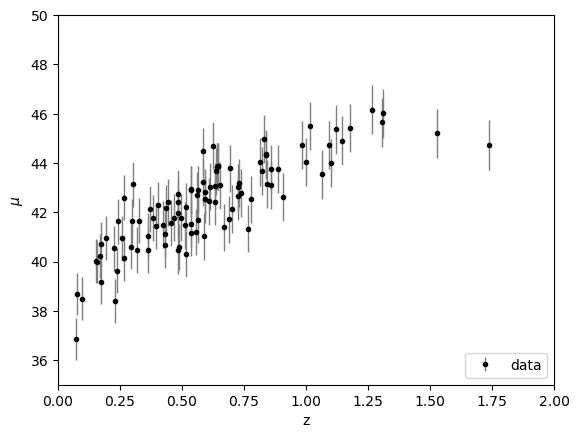

In [5]:
z_sample, mu_sample, dmu = generate_mu_z(100, random_state=1234) # YOU CANNOT CHANGE THIS

plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
plt.xlabel("z")
plt.ylabel("$\mu$")
plt.legend(loc='lower right')
plt.xlim(0,2)
plt.ylim(35,50)
plt.show()

## GPR

### $l = 2$, RBF

In [ ]:
x = np.linspace(0, 2, 100)

RBF_1 = kernels.RBF(1/0.5, (1/0.5, 1/0.5))
gp_1 = GaussianProcessRegressor(kernel=RBF_1, 
                                alpha=dmu**2,
                               random_state=0, normalize_y=True, optimizer=None)
gp_1.fit(z_sample[:, None], mu_sample)

f_1, f_1_err = gp_1.predict(x[:, None], 
                         return_std=True)

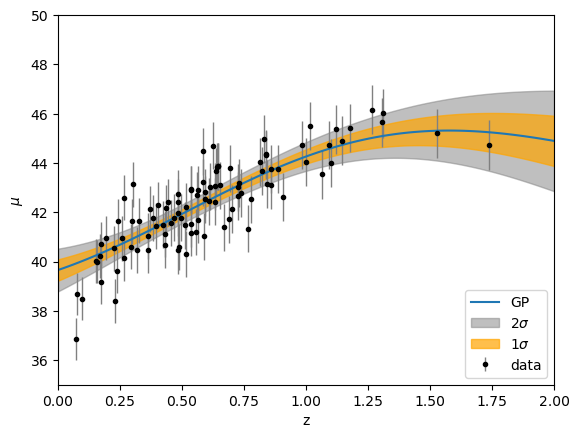

In [ ]:
plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
plt.plot(x, f_1, label='GP')
plt.fill_between(x, f_1-2*f_1_err, f_1+2*f_1_err, color='gray', alpha=0.5, label='$2\sigma$')
plt.fill_between(x, f_1-f_1_err, f_1+f_1_err, color='orange', alpha=0.7, label='$1\sigma$')
plt.xlabel("z")
plt.ylabel("$\mu$")
plt.legend(loc='lower right')
plt.xlim(0,2)
plt.ylim(35,50)
plt.show()

### Different Choiches of l and RBF kernel

In [38]:
nu = [2, 1, 0.5, 0.2]

RBF = [kernels.RBF(1/nu_i, (1/nu_i, 1/nu_i)) for nu_i in nu]

gp_rbf = [GaussianProcessRegressor(kernel=RBF_i,
                                alpha=dmu**2,
                                 random_state=0, normalize_y=True, optimizer=None) for RBF_i in RBF]
for gp_rbf_i in gp_rbf:
    gp_rbf_i.fit(z_sample[:, None], mu_sample)
f_rbf = [gp_rbf_i.predict(x[:, None], return_std=True)[0] for gp_rbf_i in gp_rbf]
f_err_rbf = [gp_rbf_i.predict(x[:, None], return_std=True)[1] for gp_rbf_i in gp_rbf]

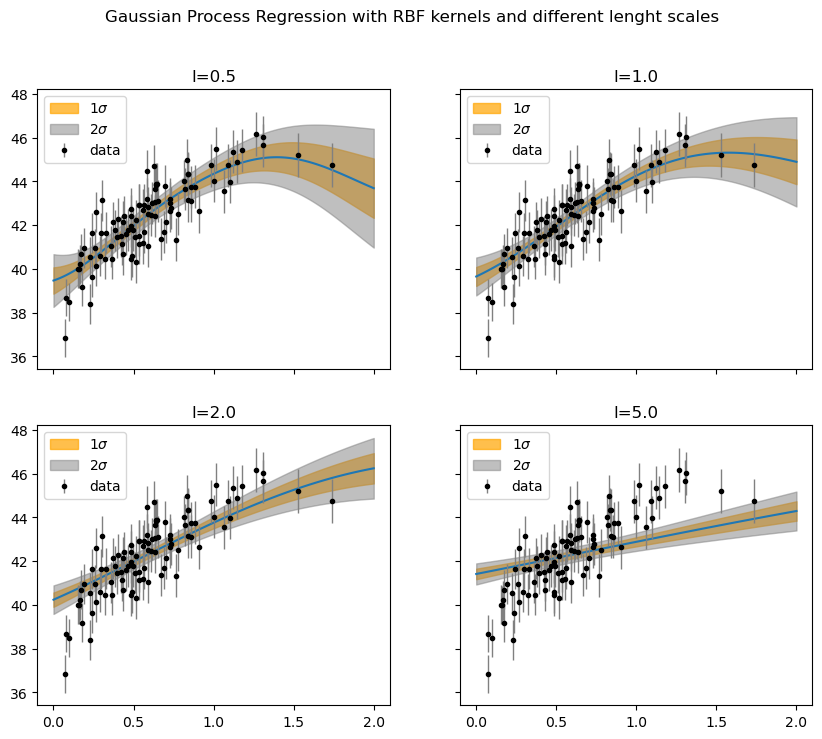

In [41]:
figure, ax = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

figure.suptitle("Gaussian Process Regression with RBF kernels and different lenght scales")
for i in range(4):
    ax[i//2, i%2].plot(x, f_rbf[i])
    ax[i//2, i%2].errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
    ax[i//2, i%2].fill_between(x, f_rbf[i]-f_err_rbf[i], f_rbf[i]+f_err_rbf[i], color='orange', alpha=0.7, label='$1\sigma$')
    ax[i//2, i%2].fill_between(x, f_rbf[i]-2*f_err_rbf[i], f_rbf[i]+2*f_err_rbf[i], color='gray', alpha=0.5, label='$2\sigma$')
    ax[i//2, i%2].set_title(f'l={1/nu[i]}')
    ax[i//2, i%2].legend()

### Different Choiches of l and Matern kernel

In [44]:
MAT = [kernels.Matern(1/nu_i, (1/nu_i, 1/nu_i)) for nu_i in nu]

gp_mat = [GaussianProcessRegressor(kernel=MAT_i,
                                alpha=dmu**2,
                                 random_state=0, normalize_y=True, optimizer=None) for MAT_i in MAT]
for gp_mat_i in gp_mat:
    gp_mat_i.fit(z_sample[:, None], mu_sample)
f_mat = [gp_mat_i.predict(x[:, None], return_std=True)[0] for gp_mat_i in gp_mat]
f_err_mat = [gp_mat_i.predict(x[:, None], return_std=True)[1] for gp_mat_i in gp_mat]

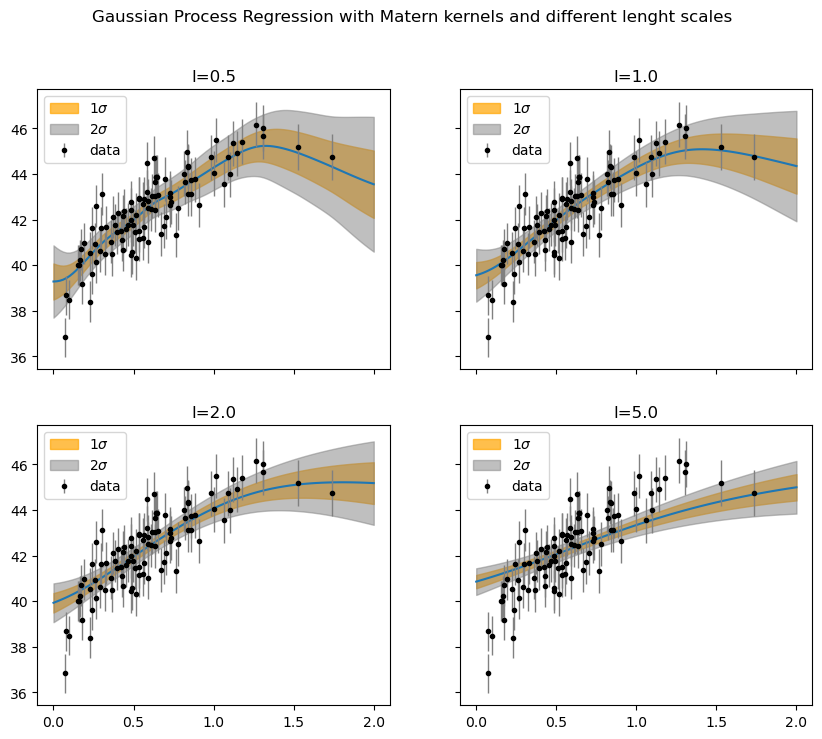

In [45]:
figure, ax = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

figure.suptitle("Gaussian Process Regression with Matern kernels and different lenght scales")
for i in range(4):
    ax[i//2, i%2].plot(x, f_mat[i])
    ax[i//2, i%2].errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
    ax[i//2, i%2].fill_between(x, f_mat[i]-f_err_mat[i], f_mat[i]+f_err_mat[i], color='orange', alpha=0.7, label='$1\sigma$')
    ax[i//2, i%2].fill_between(x, f_mat[i]-2*f_err_mat[i], f_mat[i]+2*f_err_mat[i], color='gray', alpha=0.5, label='$2\sigma$')
    ax[i//2, i%2].set_title(f'l={1/nu[i]}')
    ax[i//2, i%2].legend()

### Optimized l for different Kernels

In [65]:
RBF = kernels.RBF(10, (1e-3, 1e3))
MAT = kernels.Matern(10, (1e-3, 1e3))
CK = kernels.ConstantKernel(1, (1e-3, 1e3))
RQK = kernels.RationalQuadratic(1, 1, (1e-3, 1e3), (1e-3, 1e3))
RBF_dot_CK = RBF * CK
RBF_plus_CK = RBF + CK
gp_rbf = GaussianProcessRegressor(kernel=RBF, alpha=dmu**2, random_state=0, normalize_y=True)
gp_mat = GaussianProcessRegressor(kernel=MAT, alpha=dmu**2, random_state=0, normalize_y=True)
gp_ck = GaussianProcessRegressor(kernel=CK, alpha=dmu**2, random_state=0, normalize_y=True)
gp_rqk = GaussianProcessRegressor(kernel=RQK, alpha=dmu**2, random_state=0, normalize_y=True)
gp_rbf_dot_ck = GaussianProcessRegressor(kernel=RBF_dot_CK, alpha=dmu**2, random_state=0, normalize_y=True)
gp_rbf_plus_ck = GaussianProcessRegressor(kernel=RBF_plus_CK, alpha=dmu**2, random_state=0, normalize_y=True)

gprs = [gp_rbf, gp_mat, gp_ck, gp_rqk, gp_rbf_dot_ck, gp_rbf_plus_ck]

for gp in gprs:
    gp.fit(z_sample[:, None], mu_sample)

f = [gp.predict(x[:, None], return_std=True)[0] for gp in gprs]
f_err = [gp.predict(x[:, None], return_std=True)[1] for gp in gprs]

c:\Users\nicco\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter constant_value is close to the specified lower bound 0.001. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\nicco\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter alpha is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\nicco\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__constant_value is close to the specified lower bound 0.001. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


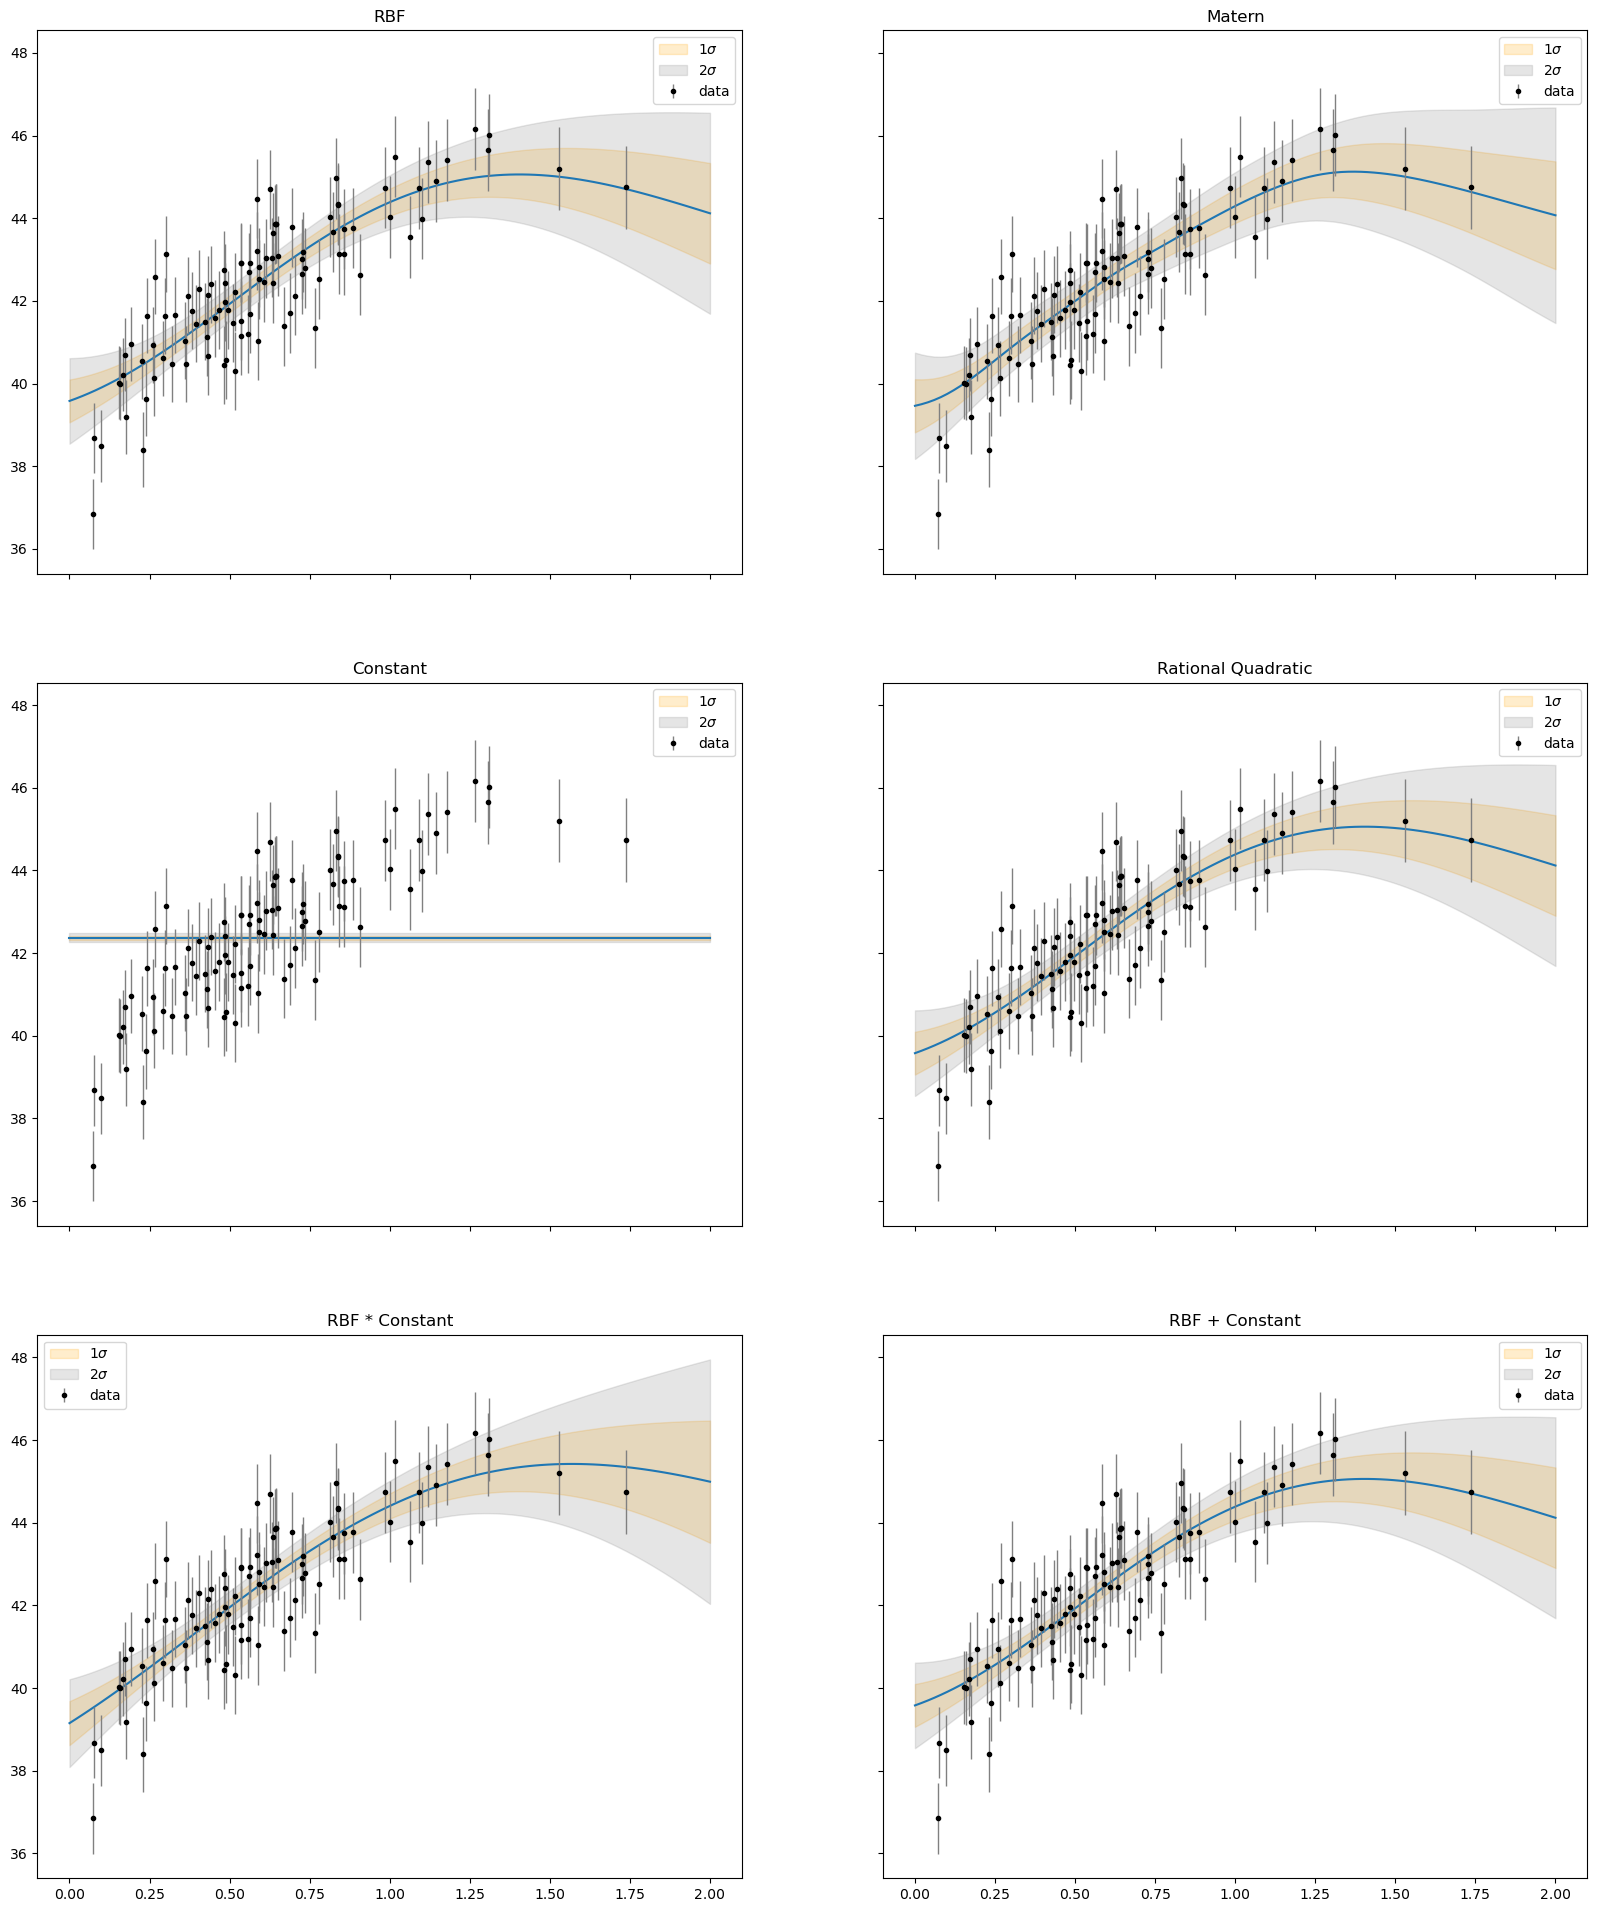

In [66]:
figures, ax = plt.subplots(3, 2, figsize=(20, 24), sharex=True, sharey=True)
kernel_names = ['RBF', 'Matern', 'Constant', 'Rational Quadratic', 'RBF * Constant', 'RBF + Constant']
for i in range(6):
    ax[i//2, i%2].plot(x, f[i])
    ax[i//2, i%2].errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
    ax[i//2, i%2].fill_between(x, f[i]-f_err[i], f[i]+f_err[i], color='orange', alpha=0.2, label='$1\sigma$')
    ax[i//2, i%2].fill_between(x, f[i]-2*f_err[i], f[i]+2*f_err[i], color='gray', alpha=0.2, label='$2\sigma$')
    ax[i//2, i%2].set_title(kernel_names[i])
    ax[i//2, i%2].legend()

## Generate mu sample

### Redshift density

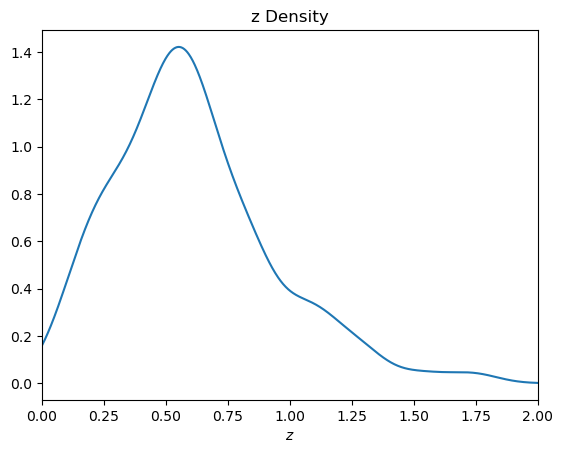

In [76]:
z_grid = np.linspace(0, 2, 1000)

kde = KD(bandwidth=0.1, kernel="gaussian")
kde.fit(z_sample[:, None])

plt.plot(z_grid, np.exp(kde.score_samples(z_grid[:, None])))
plt.xlabel(r"$z$")
plt.xlim(0, 2)
plt.title(r"z Density")
plt.show()

### $\mu$ samples

In [80]:
z_sample = kde.sample(1000, random_state=1234).flatten()
y_sample_means, y_sample_stds = gprs[4].predict(z_sample[:, None], return_std=True)
y_sample = np.random.normal(y_sample_means, y_sample_stds)

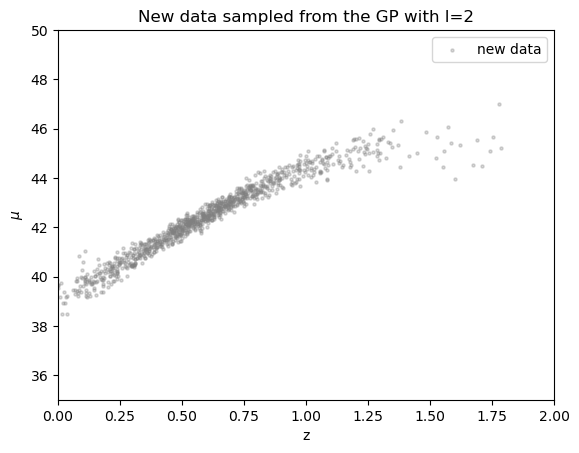

In [86]:
plt.scatter(z_sample, y_sample, s=5, color='gray', alpha=0.3, label='new data')
plt.title("New data sampled from the GP with l=2")
plt.xlabel("z")
plt.ylabel("$\mu$")
plt.legend()
plt.xlim(0,2)
plt.ylim(35,50)
plt.show()

### Part 3 (for the exam)

*(I know this assignment is longer and more convoluted, but we're getting towards the end of the class and it's important to draw connections between the different things we've done)*

We now have a suite of **data-driven** predictive models for our supernova dataset (from polynomials to GPR). That is: we can faithfully predict how a future redshift/distance measurement will look like given the current sample.

This is already great and these kind of tools are immensely useful in a variety of contexts (also involving a lot of money: suppose you want to predict how much a give financial asset will perform on tomorrow's stock market... You  might not really care about expressing the underlying financial model in simple terms, as long as your investments are profitable).

For the case of supernovae, however, we have do have physical theory which is $\Lambda$CDM. We can do a **parametric** fit (and hopehully by now the difference between "parametric" and "data driven" fit is clear in your head)

- First, refresh your cosmology and write down the predicted relationship between the distance module $\mu$ and the redshift $\sigma$. *Hint* I always forget these things, my to-go reference is [Hogg (2010)](https://arxiv.org/abs/astro-ph/9905116). The answer is:

$$\mu = 5 \log \left( \frac{c/H_0} {10 {\rm pc}}(1+z)\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z^3)+\Omega_\Lambda}} \right) $$

- Assuming a flat Universe,  we have a parametric non-linear model for $\mu(z)$ that depends on two parameters, the Hubble constant $H_0$ and the matter content of the Universe $\Omega_m$
- It's a very non-linear model. Fit it to the data, however you want to do it, using tecniques we've seen throughout the course. Some ideas:
    - Set up a Bayesian framework and use MCMC. 
    - Set up a fully-connected neural network (see end of the class).

- What are the measured value of $H_0$ and $\Omega_m$. What's they errors? Are they correlated?
- How would a model without dark energy (i.e. $\Omega_m=1$) perform? Do these data contain evidence of dark energy? (Hint: this is a model selection problem!)





In [65]:
from scipy.integrate import quad
from scipy import constants
import emcee
import warnings; warnings.simplefilter('ignore')
import corner
from IPython.display import display, Math

def model(H0, Om, z):
     
    cosmo = LambdaCDM(H0=H0, Om0=Om, Ode0=1-Om)
    return cosmo.distmod(z).value                                                                                         


def log_Likelihood(x, data):
    # Gaussian likelihood 
    H0, Om = x
        
    if Om<0:
        return -np.inf
    else:
        mu_model = model(H0, Om, data[:, 0])
        
    return np.sum(-(data[:, 1] - mu_model)**2 /(2 *data[:, 2]**2))

def log_Prior(x):
    
    if not (0 < x[0] < 100 and 0 < x[1] < 1):
        return -np.inf
    return 0.0

def myLogPosterior(x, data):
    return log_Likelihood(x, data) + log_Prior(x)

In [59]:
data = np.column_stack((z_sample, mu_sample, dmu))

ndim = 2
nwalkers = 5
nsteps = 50000
burn = 1000   

p0 = np.random.rand(nwalkers, ndim) * [100, 1]

sampler = emcee.EnsembleSampler(nwalkers, ndim, myLogPosterior, args=[data])
sampler.run_mcmc(p0, nsteps, progress=True);

  0%|          | 0/50000 [00:00<?, ?it/s]

100%|██████████| 50000/50000 [02:48<00:00, 297.32it/s]


### Trace Plots

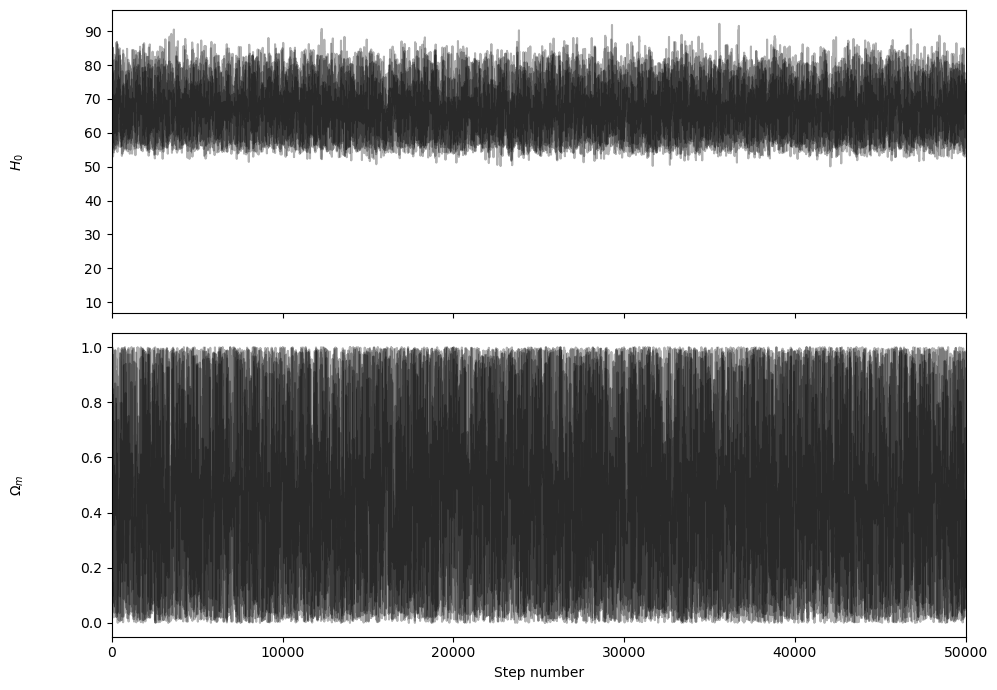

In [60]:
samples = sampler.get_chain()
labels = [r"$H_0$", r"$\Omega_m$"]
ndim = len(labels)

fig, axes = plt.subplots(ndim, figsize=(10, 7), sharex=True)

for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    if labels[i] == "a":
        ax.set_yscale('log')
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("Step number");
plt.tight_layout()
plt.show()

In [61]:
tau = sampler.get_autocorr_time()

print(f"Tau (post burn-in): {tau}")
print(f"Max tau: {np.max(tau):.2f}") 

Tau (post burn-in): [49.18715463 50.4060188 ]
Max tau: 50.41


In [62]:
thin = int(np.max(tau+1))
burn = int(2 * np.max(tau))
flat_samples = sampler.get_chain(discard=burn, thin=thin, flat=True)

### Corner

$H_0$ = 66.520 (+7.079, -6.090)
$\Omega_m$ = 0.444 (+0.314, -0.255)


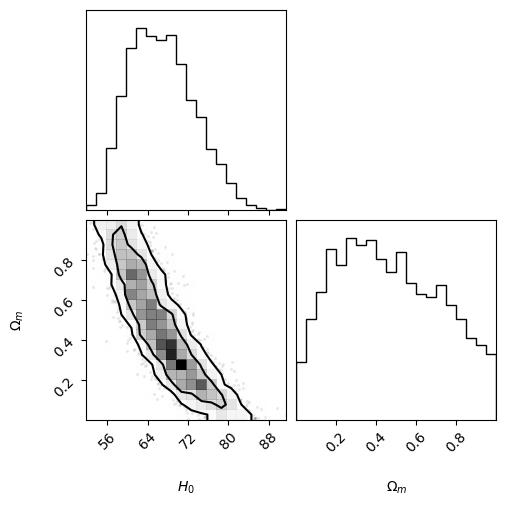

In [63]:
fig = corner.corner(
    flat_samples, labels=labels, levels=[0.68,0.95]
);

medians = np.median(flat_samples, axis=0)
for i in range(ndim):
    q = np.percentile(flat_samples[:, i], [16, 84])
    print(f"{labels[i]} = {medians[i]:.3f} (+{q[1]-medians[i]:.3f}, -{medians[i]-q[0]:.3f})")

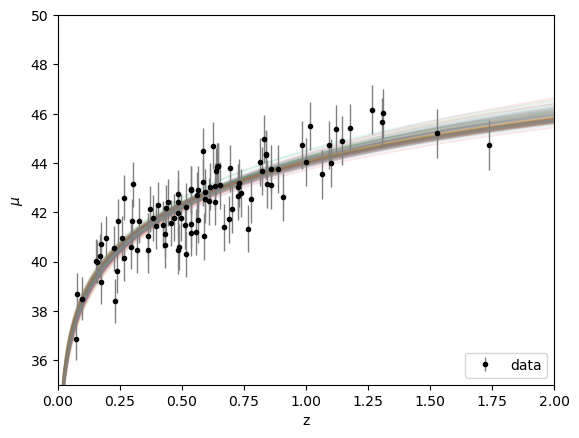

In [64]:
samples = flat_samples[np.random.choice(len(flat_samples), size = 100)]

x_grid = np.linspace(0,2,int(1e3))
models = np.array([model(samples[i, :], x_grid) for i in range(len(samples))])

plt.plot(x_grid, models.T, alpha = 0.1)
plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
plt.xlabel("z")
plt.ylabel("$\mu$")
plt.legend(loc='lower right')
plt.xlim(0,2)
plt.ylim(35,50)
plt.show()

## Model Comparison


In [66]:
import dynesty
import scipy.stats as sp
from dynesty import plotting as dyplot
from dynesty import utils as dyfunc

In [82]:
def log_Likelihood(x, data, DM):
    
    if DM =='DM':
        H0, Om = x
        y_fit = model(H0, Om, data[:,0])
    elif DM == 'NoDM':
        H0 = x[0]
        y_fit = model(H0, 1, data[:,0])
        
    return np.sum(-(data[:, 1] - y_fit)**2 /(2 *data[:, 2]**2))

def ptform_dm(u):

    x = np.array(u)  

    x[0] = sp.uniform(loc=0,scale=100).ppf(u[0])
    x[1] = sp.uniform(loc = 0, scale = 1).ppf(u[1])

    return x

def ptform_no_dm(u):
    x = np.array(u)  

    x[0] = sp.uniform(loc=0,scale=100).ppf(u[0])

    return x

### DM

In [91]:
ndim = 2

sampler_dm = dynesty.NestedSampler(log_Likelihood, ptform_dm, ndim, logl_args=[data,'DM'] ,nlive=200)
sampler_dm.run_nested()
sresults_dm = sampler_dm.results

935it [00:17, 53.57it/s, +200 | bound: 2 | nc: 1 | ncall: 8198 | eff(%): 14.191 | loglstar:   -inf < -46.385 <    inf | logz: -49.392 +/-  0.101 | dlogz:  0.001 >  0.209]


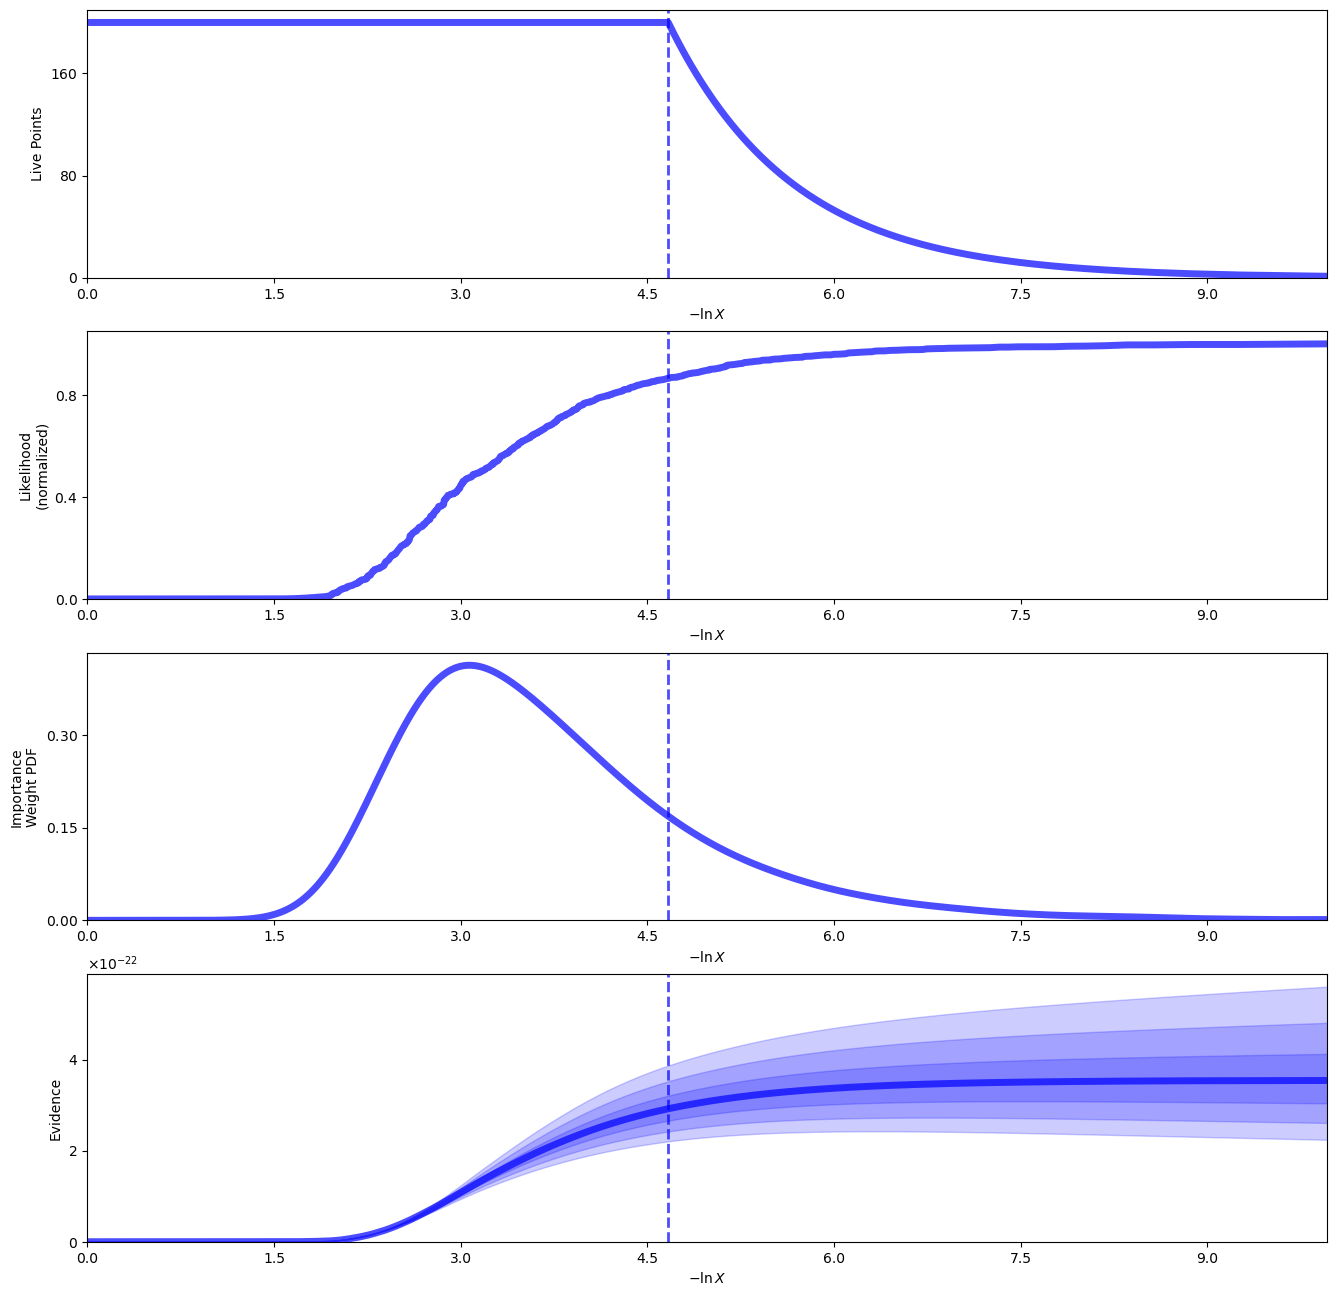

In [92]:
rfig, raxes = dyplot.runplot(sresults_dm)

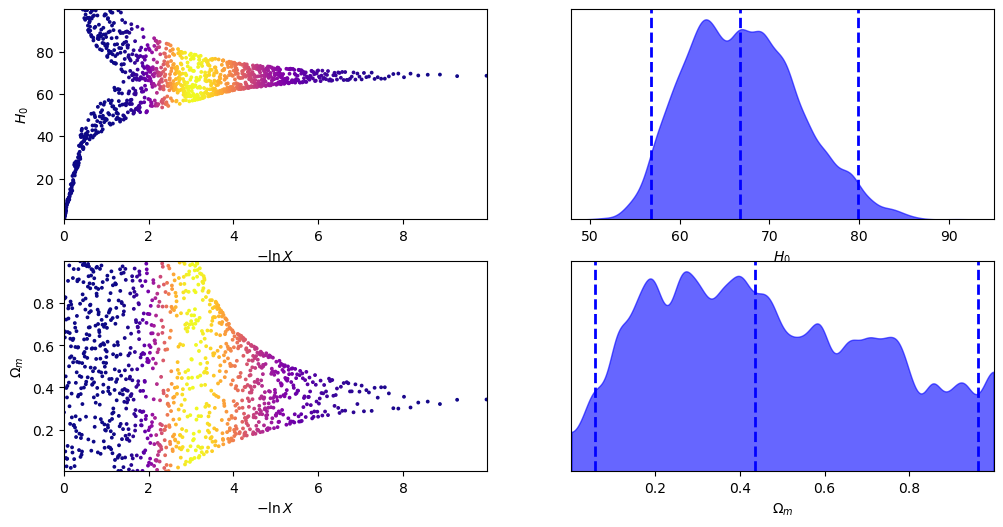

In [93]:
tfig, taxes = dyplot.traceplot(sresults_dm, labels=labels)

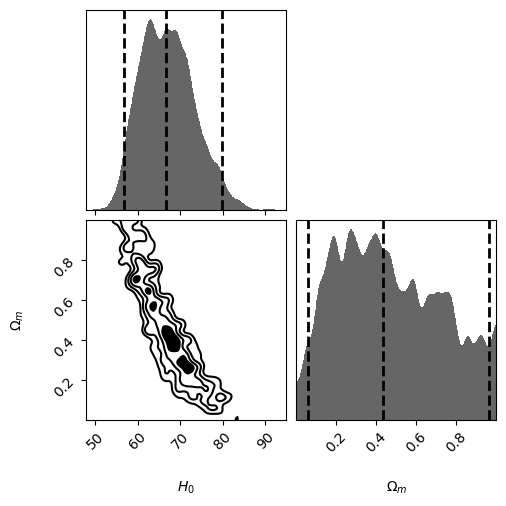

In [94]:
cfig, caxes = dyplot.cornerplot(sresults_dm, labels=labels);

### No DM

In [84]:
ndim = 1

sampler_no_dm = dynesty.NestedSampler(log_Likelihood, ptform_no_dm, ndim, logl_args=[data,'NoDM'] ,nlive=200)
sampler_no_dm.run_nested()
sresults_no_dm = sampler_no_dm.results

884it [00:12, 70.50it/s, +200 | bound: 2 | nc: 1 | ncall: 7826 | eff(%): 14.215 | loglstar:   -inf < -47.102 <    inf | logz: -49.843 +/-  0.095 | dlogz:  0.001 >  0.209]


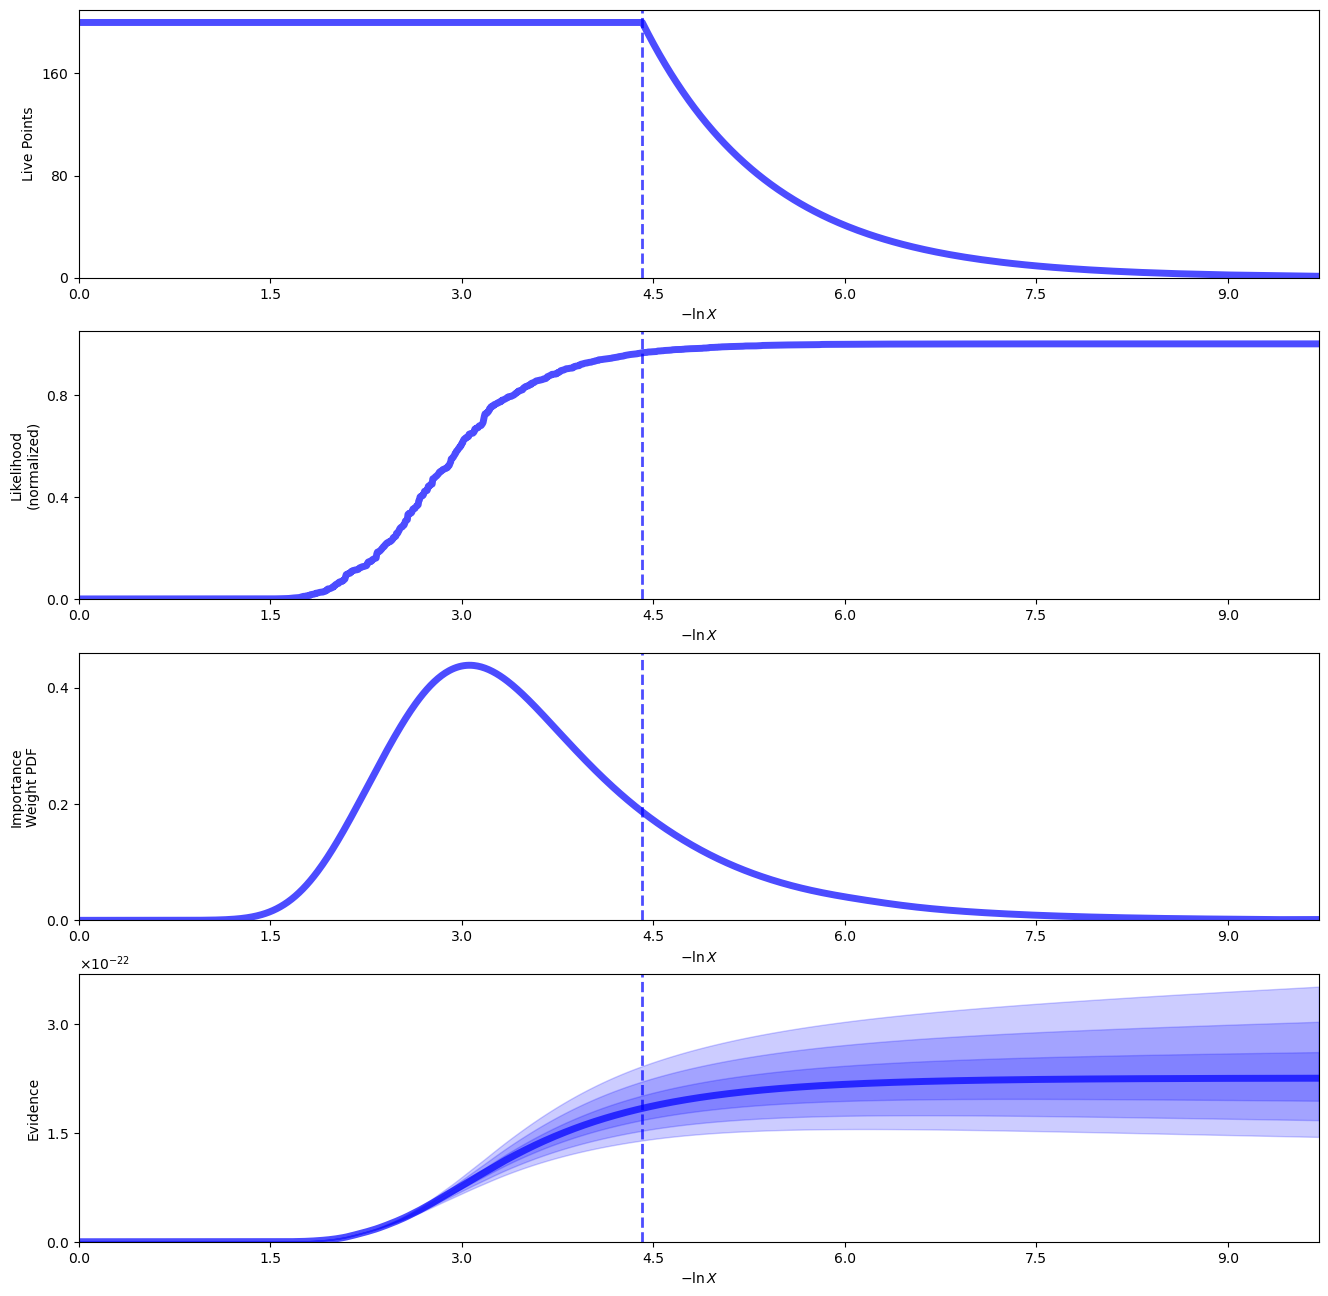

In [85]:
rfig, raxes = dyplot.runplot(sresults_no_dm)

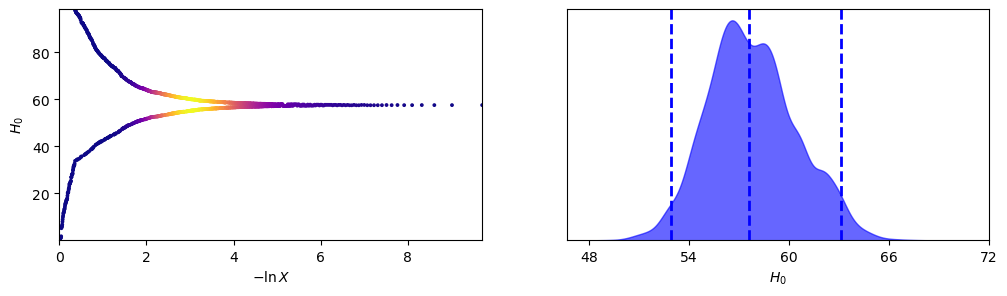

In [87]:
tfig, taxes = dyplot.traceplot(sresults_no_dm, labels=labels)

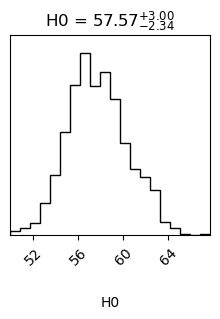

In [107]:
samples = sresults_no_dm.samples  # samples
weights = np.exp(sresults_no_dm.logwt - sresults_no_dm.logz[-1])  # normalized weights

# Resample weighted samples.
samples_no_dm = dyfunc.resample_equal(samples, weights)

fig = corner.corner(
    samples_no_dm, labels=["H0"], levels=[0.68,0.95], show_titles=True
);

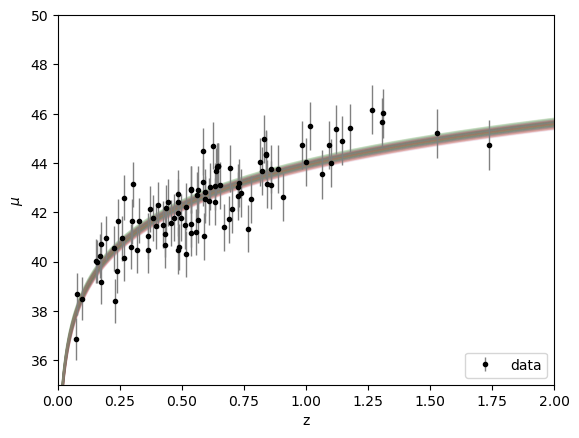

In [108]:
samples_no_dm = samples_no_dm[np.random.choice(len(samples_no_dm), size = 100)].flatten()

x_grid = np.linspace(0,2,int(1e3))
models = np.array([model(samples_no_dm[i], 1, x_grid) for i in range(len(samples_no_dm))])

plt.plot(x_grid, models.T, alpha = 0.1)
plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
plt.xlabel("z")
plt.ylabel("$\mu$")
plt.legend(loc='lower right')
plt.xlim(0,2)
plt.ylim(35,50)
plt.show()

### Comparison

In [95]:
# Extract sampling results.
samples_dm = sresults_dm.samples  # samples
weights_dm = np.exp(sresults_dm.logwt - sresults_dm.logz[-1])  # normalized weights

samples_no_dm = sresults_no_dm.samples  # samples
weights_no_dm = np.exp(sresults_no_dm.logwt - sresults_no_dm.logz[-1])  # normalized weights


evidence_dm = sresults_dm.logz[-1] #evidence
print("Bayesian evidence for the model with dark matter", np.exp(evidence_dm))

evidence_no_dm = sresults_no_dm.logz[-1] #evidence
print("Bayesian evidence for the model without dark matter", np.exp(evidence_no_dm))

# Compute 10%-90% quantiles.
quantiles_dm = [dyfunc.quantile(samps, [0.16, 0.84], weights=weights_dm)
             for samps in samples_dm.T]
print('68% parameter credible regions are:\n ' + str(quantiles_dm) + '\n')

# Compute 10%-90% quantiles.
quantiles_no_dm = [dyfunc.quantile(samps, [0.16, 0.84], weights=weights_no_dm)
             for samps in samples_no_dm.T]
print('68% parameter credible regions are:\n ' + str(quantiles_no_dm) + '\n')


# Compute weighted mean and covariance.
mean_dm, cov_dm = dyfunc.mean_and_cov(samples_dm, weights_dm)
print('Mean and covariance of parameters are: ' + str(mean_dm) + '\n' + str(cov_dm))

mean_no_dm, cov_no_dm = dyfunc.mean_and_cov(samples_no_dm, weights_no_dm)
print('Mean and covariance of parameters are: ' + str(mean_no_dm) + '\n' + str(cov_no_dm))

# Generate a new set of results with statistical+sampling uncertainties.
#results_sim = dyfunc.simulate_run(sresults)

Bayesian evidence for the model with dark matter 3.543008955575251e-22
Bayesian evidence for the model without dark matter 2.2565746209966386e-22
68% parameter credible regions are:
 [[60.531335085272524, 73.21872080305859], [0.1880552704781713, 0.76013832007472]]

68% parameter credible regions are:
 [[55.23821810434772, 60.5776639982675]]

Mean and covariance of parameters are: [67.00239288  0.46580428]
[[38.28010924 -1.37295039]
 [-1.37295039  0.06554829]]
Mean and covariance of parameters are: [57.79134825]
[[6.98711109]]
